In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [18]:
# 2. Load dataset
# Put the CSV file in the same folder as this notebook, then update the filename if needed.
file_path = "covid_dataset.csv"

data = pd.read_csv(file_path)

print("Original Dataset")
display(data.head())
print("\nDataset shape:", data.shape)


Original Dataset


,USMER,MEDICAL_UNIT,SEX,PATIENT_TYPE,DATE_DIED,INTUBED,PNEUMONIA,AGE,PREGNANT,DIABETES,...,ASTHMA,INMSUPR,HIPERTENSION,OTHER_DISEASE,CARDIOVASCULAR,OBESITY,RENAL_CHRONIC,TOBACCO,CLASIFFICATION_FINAL,ICU
0,2,1,1,1,03/05/2020,97,1,65,2,2,...,2,2,1,2,2,2,2,2,3,97
1,2,1,2,1,03/06/2020,97,1,72,97,2,...,2,2,1,2,2,1,1,2,5,97
2,2,1,2,2,09/06/2020,1,2,55,97,1,...,2,2,2,2,2,2,2,2,3,2
3,2,1,1,1,12/06/2020,97,2,53,2,2,...,2,2,2,2,2,2,2,2,7,97
4,2,1,2,1,21/06/2020,97,2,68,97,1,...,2,2,1,2,2,2,2,2,3,97



Dataset shape: (1048575, 21)


In [3]:
# 3. Inspect the dataset
display(data.describe)
print("\nMissing values in each column:")
print(data.isnull().sum())


<bound method NDFrame.describe of          USMER  MEDICAL_UNIT  SEX  PATIENT_TYPE   DATE_DIED  INTUBED  \
0            2             1    1             1  03/05/2020       97   
1            2             1    2             1  03/06/2020       97   
2            2             1    2             2  09/06/2020        1   
3            2             1    1             1  12/06/2020       97   
4            2             1    2             1  21/06/2020       97   
...        ...           ...  ...           ...         ...      ...   
1048570      2            13    2             1  9999-99-99       97   
1048571      1            13    2             2  9999-99-99        2   
1048572      2            13    2             1  9999-99-99       97   
1048573      2            13    2             1  9999-99-99       97   
1048574      2            13    2             1  9999-99-99       97   

         PNEUMONIA  AGE  PREGNANT  DIABETES  ...  ASTHMA  INMSUPR  \
0                1   65         


Missing values in each column:
USMER                   0
MEDICAL_UNIT            0
SEX                     0
PATIENT_TYPE            0
DATE_DIED               0
INTUBED                 0
PNEUMONIA               0
AGE                     0
PREGNANT                0
DIABETES                0
COPD                    0
ASTHMA                  0
INMSUPR                 0
HIPERTENSION            0
OTHER_DISEASE           0
CARDIOVASCULAR          0
OBESITY                 0
RENAL_CHRONIC           0
TOBACCO                 0
CLASIFFICATION_FINAL    0
ICU                     0
dtype: int64


In [4]:
# 4. Prepare the target
# In this dataset, DATE_DIED = '9999-99-99' indicates that the patient did not die.
# An actual date indicates that the patient died.

data = data.copy()
data["DATE_DIED"] = data["DATE_DIED"].astype(str).str.strip()
data["DIED"] = (data["DATE_DIED"] != "9999-99-99").astype(int)

print("Target counts (0 = survived, 1 = died):")
print(data["DIED"].value_counts())


Target counts (0 = survived, 1 = died):
DIED
0    971633
1     76942
Name: count, dtype: int64


In [5]:
# 5. Separate features and target
# DATE_DIED is removed from X because it was used to create the target.
X = data.drop(columns=["DATE_DIED", "DIED"])
y = data["DIED"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())


Feature shape: (1048575, 20)
Target shape: (1048575,)


,USMER,MEDICAL_UNIT,SEX,PATIENT_TYPE,INTUBED,PNEUMONIA,AGE,PREGNANT,DIABETES,COPD,ASTHMA,INMSUPR,HIPERTENSION,OTHER_DISEASE,CARDIOVASCULAR,OBESITY,RENAL_CHRONIC,TOBACCO,CLASIFFICATION_FINAL,ICU
0,2,1,1,1,97,1,65,2,2,2,2,2,1,2,2,2,2,2,3,97
1,2,1,2,1,97,1,72,97,2,2,2,2,1,2,2,1,1,2,5,97
2,2,1,2,2,1,2,55,97,1,2,2,2,2,2,2,2,2,2,3,2
3,2,1,1,1,97,2,53,2,2,2,2,2,2,2,2,2,2,2,7,97
4,2,1,2,1,97,2,68,97,1,2,2,2,1,2,2,2,2,2,3,97


In [6]:
display(y.head())

0    1
1    1
2    1
3    1
4    1
Name: DIED, dtype: int64

In [7]:
# 6. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))


Training samples: 838860
Testing samples : 209715


In [ ]:
# 7. Handle missing / unknown values
unknown_codes = [97, 98, 99]

X_train = X_train.copy()
X_test = X_test.copy()

for col in X.columns:
    X_train.loc[X_train[col].isin(unknown_codes), col] = np.nan
    X_test.loc[X_test[col].isin(unknown_codes), col] = np.nan

imputer = SimpleImputer(strategy="median")
X_train_ready = imputer.fit_transform(X_train)
X_test_ready = imputer.transform(X_test)

print("Preprocessing complete.")
print("First five processed training rows:")
print(X_train_ready[:5])


Preprocessing complete.
First five processed training rows:
[[ 2. 12.  1.  1.  2.  2. 63.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.
   3.  2.]
 [ 2.  4.  2.  1.  2.  2. 24.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.
   5.  2.]
 [ 2. 12.  1.  1.  2.  2. 38.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.
   5.  2.]
 [ 2.  4.  1.  1.  2.  2. 31.  2.  2.  2.  2.  2.  2.  2.  2.  1.  2.  2.
   5.  2.]
 [ 1. 12.  2.  1.  2.  2. 57.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.
   6.  2.]]


In [9]:
# 8. Create and train the Decision Tree
dt = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=42,
    class_weight="balanced"
)

dt.fit(X_train_ready, y_train)
print("Decision Tree model trained.")


Decision Tree model trained.


In [10]:
# 9. Make predictions
y_pred = dt.predict(X_test_ready)


In [11]:
# 10. Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Survived", "Died"], zero_division=0))


Accuracy: 0.8648928307464893

Confusion Matrix:
[[166835  27492]
 [   842  14546]]

Classification Report:
              precision    recall  f1-score   support

    Survived       0.99      0.86      0.92    194327
        Died       0.35      0.95      0.51     15388

    accuracy                           0.86    209715
   macro avg       0.67      0.90      0.71    209715
weighted avg       0.95      0.86      0.89    209715



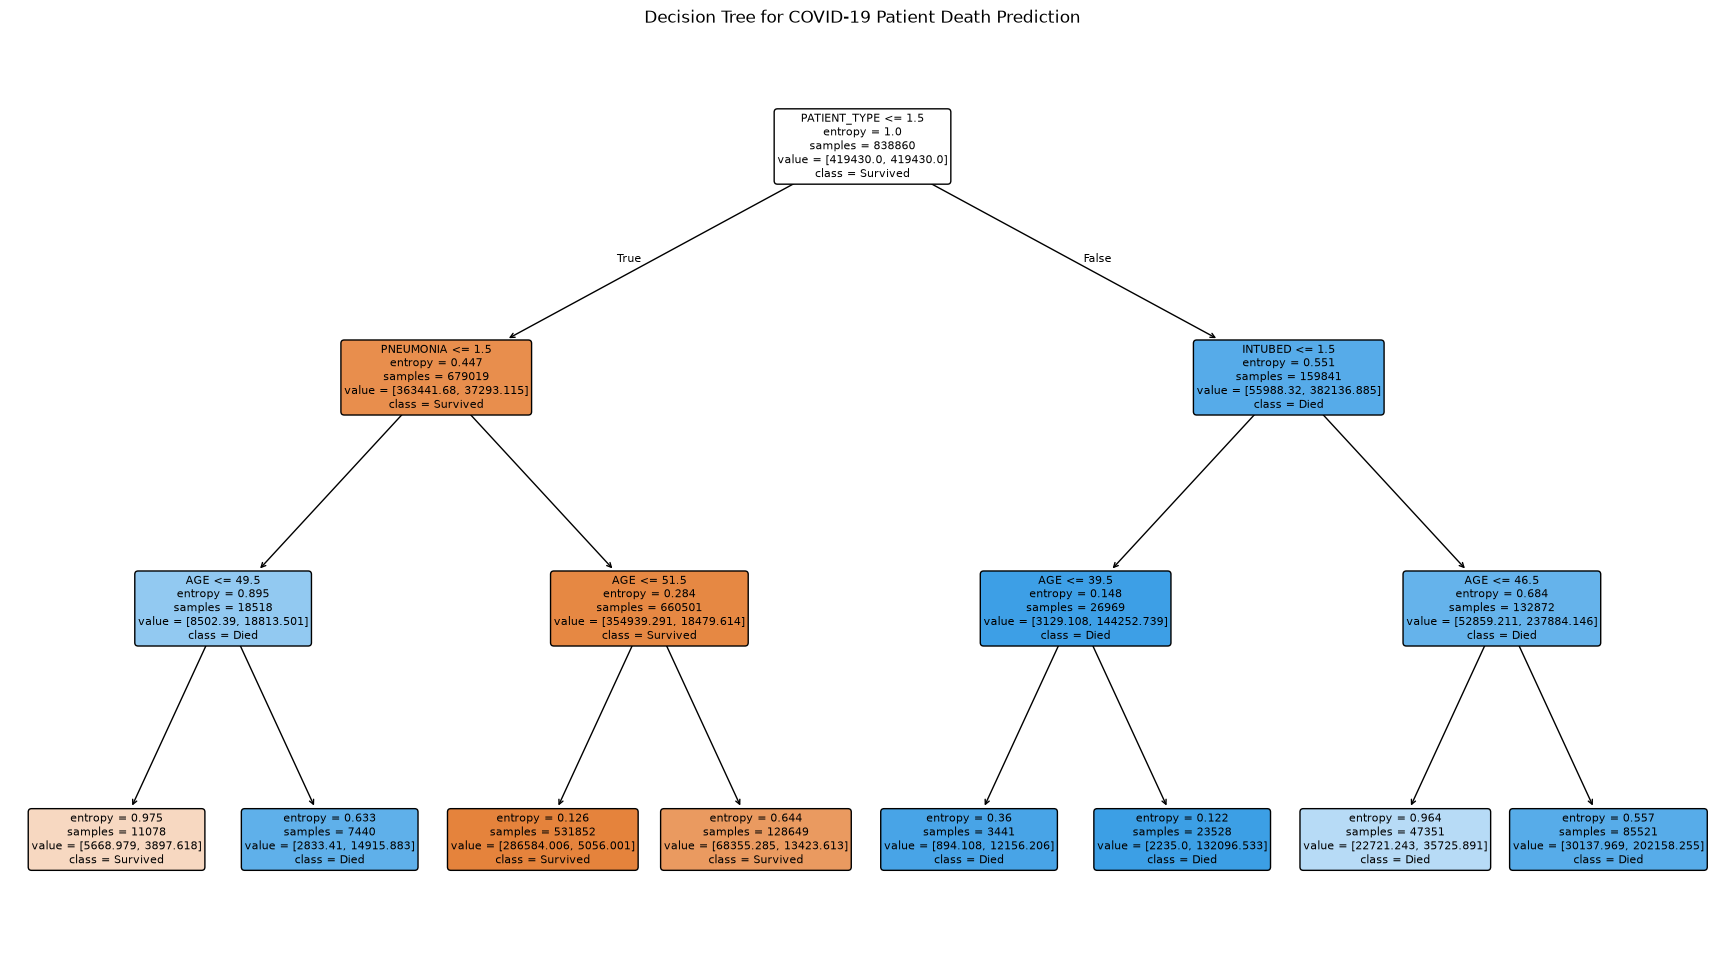

In [12]:
# 11. Visualize the Decision Tree
plt.figure(figsize=(22, 12))
plot_tree(
    dt,
    feature_names=X.columns,
    class_names=["Survived", "Died"],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree for COVID-19 Patient Death Prediction")
plt.show()


In [17]:
sample=[[2,1,1,1,97,1,65,2,2,2,2,2,1,2,2,2,2,2,3,97]]
prediction=dt.predict(sample)
print("\n pred=",prediction)
if prediction[0] == 1:
    print("\nPatient is predicted NOT to survive.")
else:
    print("\nPatient is predicted to SURVIVE.")


 pred= [1]

Patient is predicted NOT to survive.
